# Lab 03: Computer Vision Prototyping & Object Detection Pipeline
**Course:** AI Project Design and Development (AI-316)  |  **Student:** Mahad  |  **Roll No:** 231242

Tasks 1 to 6 are in this notebook. Tasks 7 and 8 (webcam) are the scripts `live_detection.py` and `surveillance_logger.py`.
Put your test images in the `images/` folder using the file names in the setup cell below.

In [1]:
import os, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

IMG_DIR = "images"
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

IMG_TRAFFIC = f"{IMG_DIR}/traffic.jpg"   # Task 1
IMG_PRODUCT = f"{IMG_DIR}/product.jpg"   # Task 2
IMG_XRAY    = f"{IMG_DIR}/xray.jpg"      # Task 3
IMG_STREET  = f"{IMG_DIR}/street.jpg"    # Task 4
IMG_SHELF   = f"{IMG_DIR}/shelf.jpg"     # Task 5
IMG_PEOPLE  = f"{IMG_DIR}/people.jpg"    # Task 6

def load_bgr(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read {path}. Put the image in the images/ folder.")
    return img

def to_rgb(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

## Task 1: Preprocessing pipeline for traffic camera footage
Steps: load the image, letterbox it to 640x640 (keeps the aspect ratio, pads the rest), then scale pixel values from [0, 255] to [0.0, 1.0].

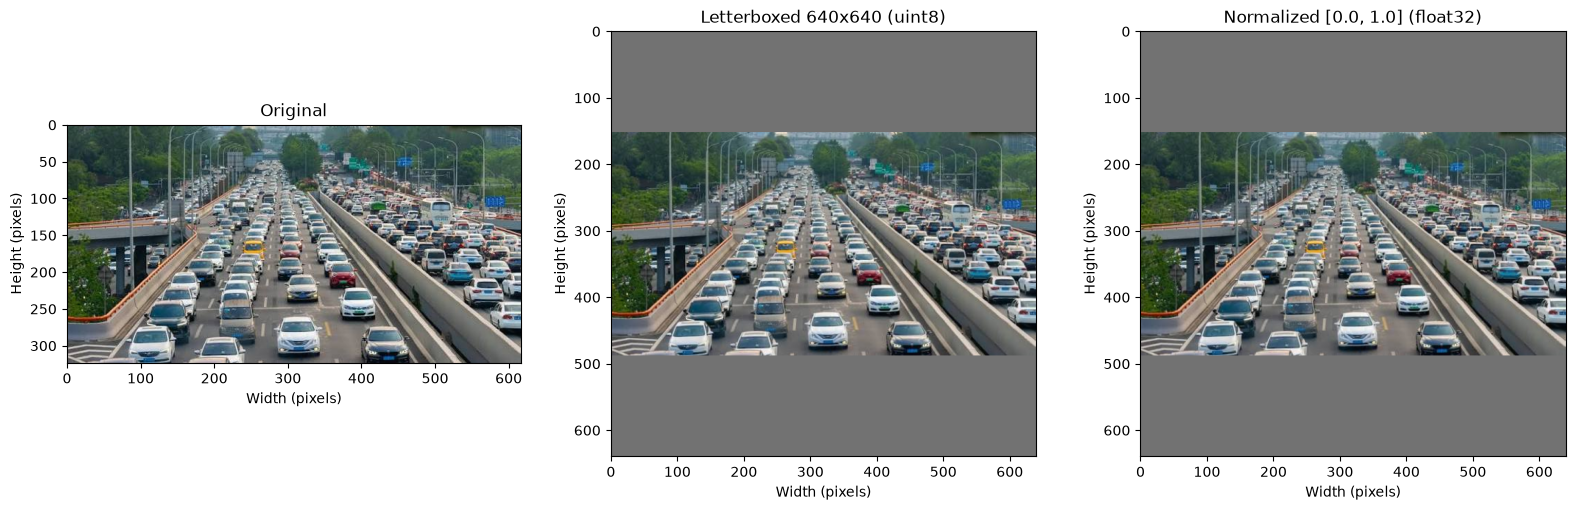

In [2]:
def letterbox(image, size=640, pad_color=(114, 114, 114)):
    h, w = image.shape[:2]
    scale = min(size / w, size / h)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)
    canvas = np.full((size, size, 3), pad_color, dtype=np.uint8)
    pad_x, pad_y = (size - new_w) // 2, (size - new_h) // 2
    canvas[pad_y:pad_y + new_h, pad_x:pad_x + new_w] = resized
    return canvas

original = load_bgr(IMG_TRAFFIC)
boxed = letterbox(original, 640)
normalized = boxed.astype(np.float32) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
stages = [(original, "Original"), (boxed, "Letterboxed 640x640 (uint8)"), (normalized, "Normalized [0.0, 1.0] (float32)")]
for ax, (im, title) in zip(axes, stages):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))   # OpenCV is BGR, matplotlib wants RGB
    ax.set_title(title)
    ax.set_xlabel("Width (pixels)")
    ax.set_ylabel("Height (pixels)")
plt.tight_layout()
plt.show()

In [3]:
stats = pd.DataFrame({
    "Stage": ["Original", "Letterboxed", "Normalized"],
    "Shape": [original.shape, boxed.shape, normalized.shape],
    "Dtype": [str(original.dtype), str(boxed.dtype), str(normalized.dtype)],
    "Min": [original.min(), boxed.min(), float(normalized.min())],
    "Max": [original.max(), boxed.max(), float(normalized.max())],
    "Mean": [round(float(original.mean()), 3), round(float(boxed.mean()), 3), round(float(normalized.mean()), 4)],
})
stats

,Stage,Shape,Dtype,Min,Max,Mean
0,Original,"(324, 617, 3)",uint8,0.0,255.0,106.3820
1,Letterboxed,"(640, 640, 3)",uint8,0.0,255.0,109.9390
2,Normalized,"(640, 640, 3)",float32,0.0,1.0,0.4311


## Task 2: Defect detection with color-space transformation and thresholding
The default HSV range targets rust (orange-brown). If your product image has a different defect color, change `LOWER` and `UPPER`.

Defect pixels: 24639 (30.44% of image)


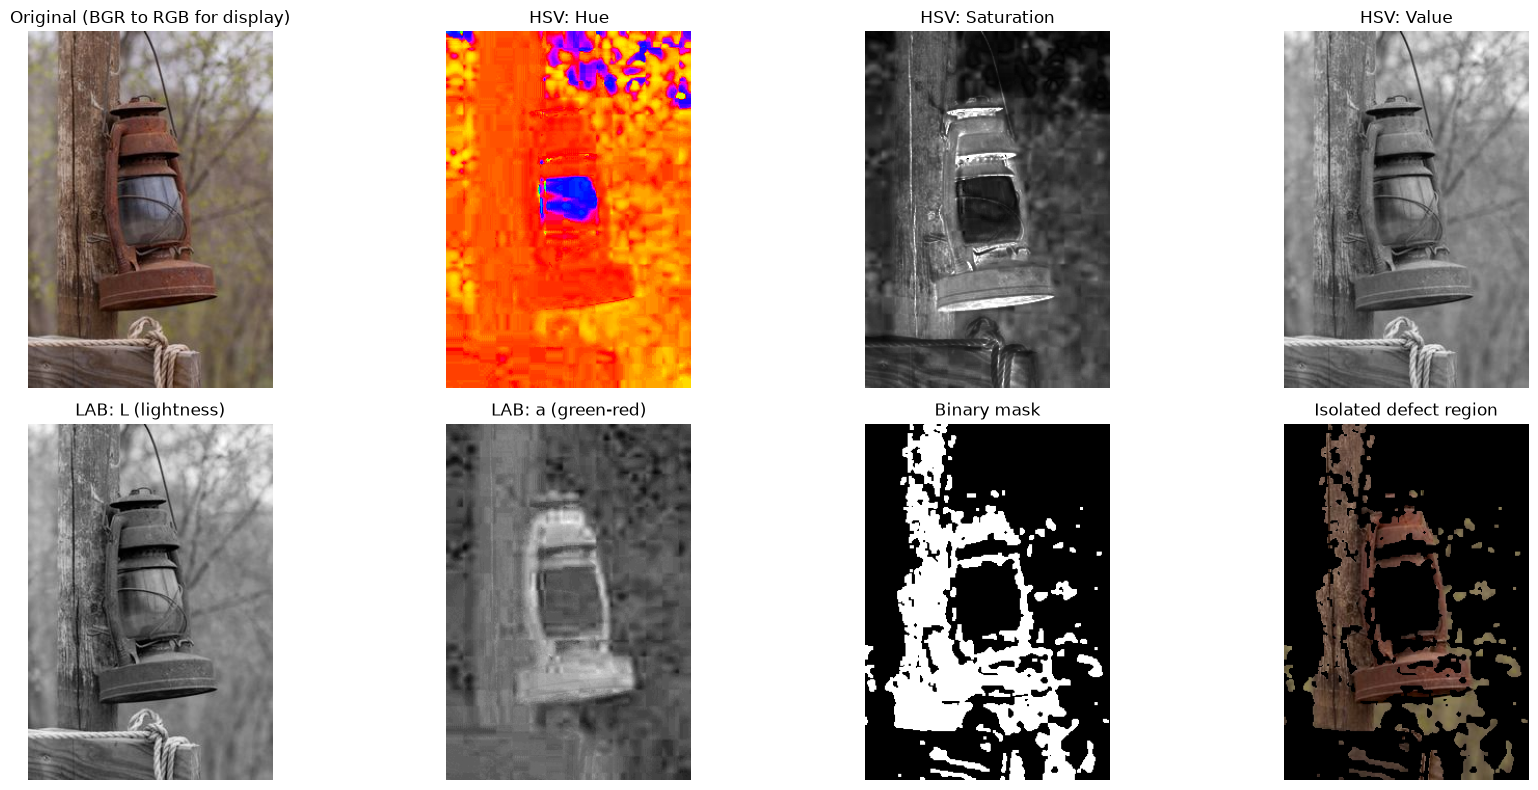

In [4]:
img = load_bgr(IMG_PRODUCT)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

LOWER = np.array([5, 80, 40])     # H, S, V lower bound
UPPER = np.array([25, 255, 255])  # H, S, V upper bound

raw_mask = cv2.inRange(hsv, LOWER, UPPER)
smooth = cv2.GaussianBlur(raw_mask, (5, 5), 0)
_, mask = cv2.threshold(smooth, 127, 255, cv2.THRESH_BINARY)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
isolated = cv2.bitwise_and(img, img, mask=mask)

print(f"Defect pixels: {int((mask > 0).sum())} ({100 * (mask > 0).mean():.2f}% of image)")

panels = [
    (to_rgb(img), "Original (BGR to RGB for display)", None),
    (hsv[:, :, 0], "HSV: Hue", "hsv"),
    (hsv[:, :, 1], "HSV: Saturation", "gray"),
    (hsv[:, :, 2], "HSV: Value", "gray"),
    (lab[:, :, 0], "LAB: L (lightness)", "gray"),
    (lab[:, :, 1], "LAB: a (green-red)", "gray"),
    (mask, "Binary mask", "gray"),
    (to_rgb(isolated), "Isolated defect region", None),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (im, title, cmap) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 3: Noise reduction and edge detection for medical imaging
The scan is loaded in grayscale. To compare filters fairly, noise is added to the clean scan (Gaussian and salt-and-pepper), each filter is applied, and the Canny edges are compared with the edges of the clean scan.
Metrics: **PSNR** (higher means closer to the clean image) and edge **precision / recall / F1** against the clean-scan edges, with a 1 pixel tolerance.

In [5]:
gray = cv2.imread(IMG_XRAY, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError(f"Could not read {IMG_XRAY}")
if max(gray.shape) > 1000:  # keep it fast
    s = 1000 / max(gray.shape)
    gray = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

rng = np.random.default_rng(42)

def add_gaussian_noise(im, sigma=20):
    return np.clip(im.astype(np.float32) + rng.normal(0, sigma, im.shape), 0, 255).astype(np.uint8)

def add_salt_pepper(im, amount=0.04):
    out = im.copy()
    r = rng.random(im.shape)
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out

noisy_images = {
    "Gaussian noise": add_gaussian_noise(gray),
    "Salt & pepper noise": add_salt_pepper(gray),
}
filters = {
    "No filter": lambda im: im,
    "Gaussian blur 5x5": lambda im: cv2.GaussianBlur(im, (5, 5), 0),
    "Median blur 5": lambda im: cv2.medianBlur(im, 5),
}

T_LOWER, T_UPPER = 50, 150
ref_edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), T_LOWER, T_UPPER)
k = np.ones((3, 3), np.uint8)

def edge_scores(pred, ref):
    pred_b, ref_b = pred > 0, ref > 0
    pred_d, ref_d = cv2.dilate(pred, k) > 0, cv2.dilate(ref, k) > 0
    precision = (pred_b & ref_d).sum() / max(pred_b.sum(), 1)
    recall = (ref_b & pred_d).sum() / max(ref_b.sum(), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    return precision, recall, f1

rows, edge_maps = [], {}
for n_name, noisy in noisy_images.items():
    for f_name, f in filters.items():
        filtered = f(noisy)
        edges = cv2.Canny(filtered, T_LOWER, T_UPPER)
        p, r, f1 = edge_scores(edges, ref_edges)
        rows.append({"Noise": n_name, "Filter": f_name,
                     "PSNR (dB)": round(cv2.PSNR(gray, filtered), 2),
                     "Edge pixels": int((edges > 0).sum()),
                     "Precision": round(p, 3), "Recall": round(r, 3), "F1": round(f1, 3)})
        edge_maps[(n_name, f_name)] = edges

results_df = pd.DataFrame(rows)
results_df

,Noise,Filter,PSNR (dB),Edge pixels,Precision,Recall,F1
0,Gaussian noise,No filter,23.73,160003,0.076,0.995,0.141
1,Gaussian noise,Gaussian blur 5x5,30.79,19404,0.407,0.819,0.544
2,Gaussian noise,Median blur 5,34.66,20284,0.409,0.831,0.549
3,Salt & pepper noise,No filter,17.73,106875,0.099,0.974,0.180
4,Salt & pepper noise,Gaussian blur 5x5,28.05,61178,0.150,0.940,0.259
5,Salt & pepper noise,Median blur 5,43.61,12116,0.726,0.930,0.815


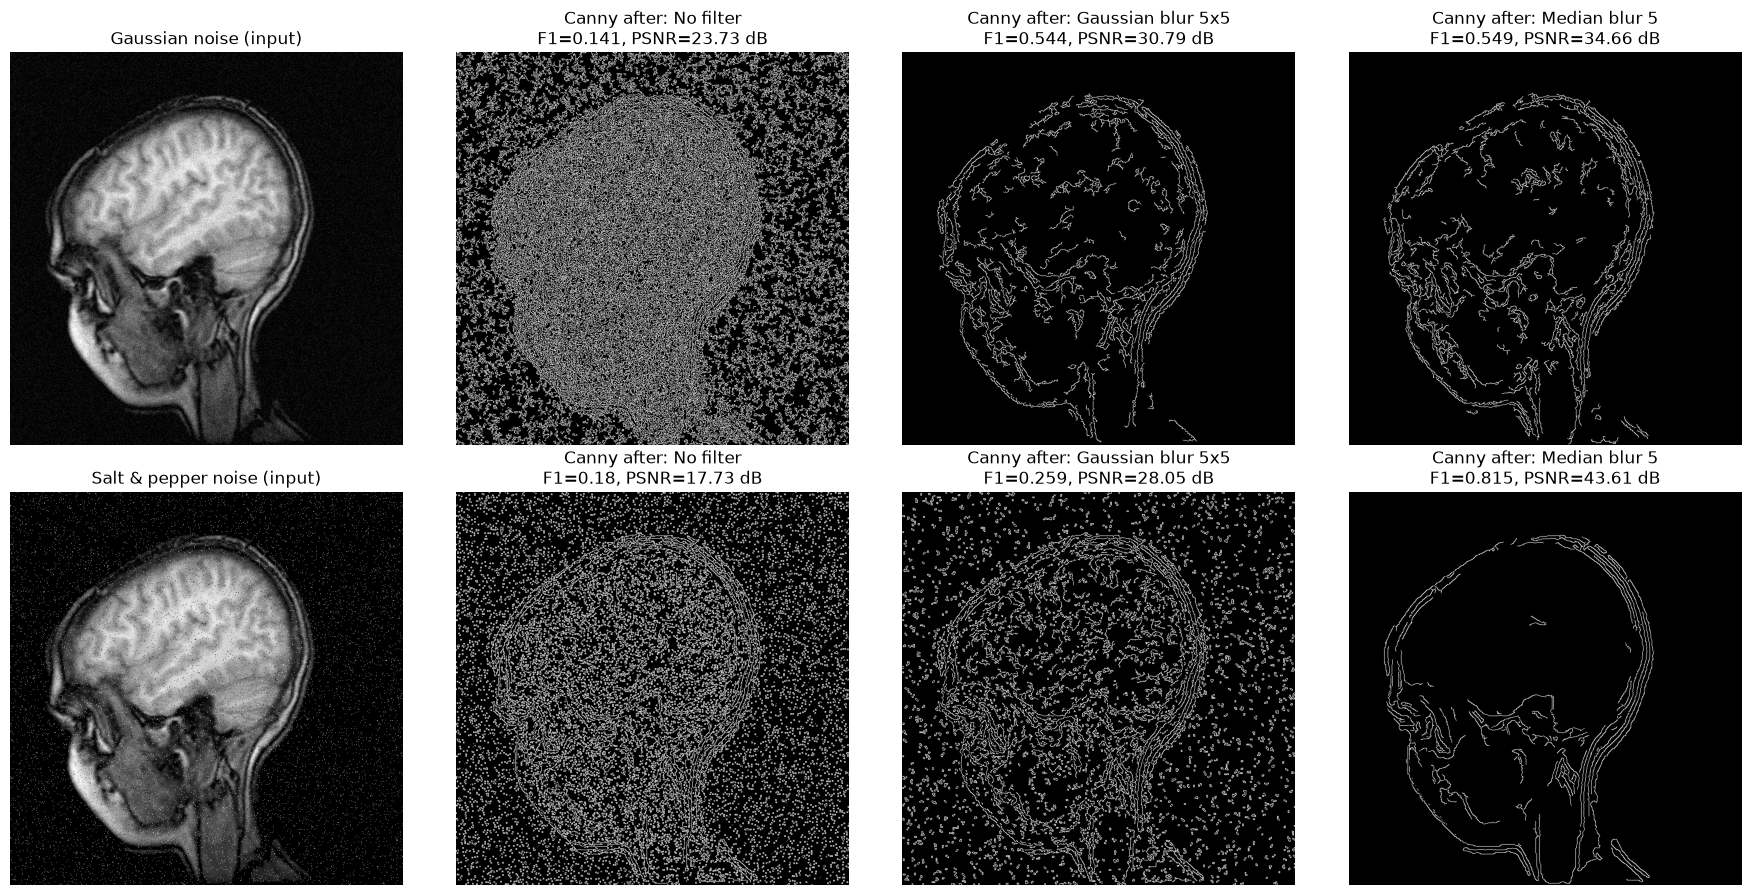

Best filter per noise type (by F1):
              Noise        Filter    F1
     Gaussian noise Median blur 5 0.549
Salt & pepper noise Median blur 5 0.815


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for i, n_name in enumerate(noisy_images):
    axes[i, 0].imshow(noisy_images[n_name], cmap="gray")
    axes[i, 0].set_title(f"{n_name} (input)")
    for j, f_name in enumerate(filters):
        ax = axes[i, j + 1]
        ax.imshow(edge_maps[(n_name, f_name)], cmap="gray")
        row = results_df[(results_df.Noise == n_name) & (results_df.Filter == f_name)].iloc[0]
        ax.set_title(f"Canny after: {f_name}\nF1={row['F1']}, PSNR={row['PSNR (dB)']} dB")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

best = results_df.loc[results_df.groupby("Noise")["F1"].idxmax()][["Noise", "Filter", "F1"]]
print("Best filter per noise type (by F1):")
print(best.to_string(index=False))

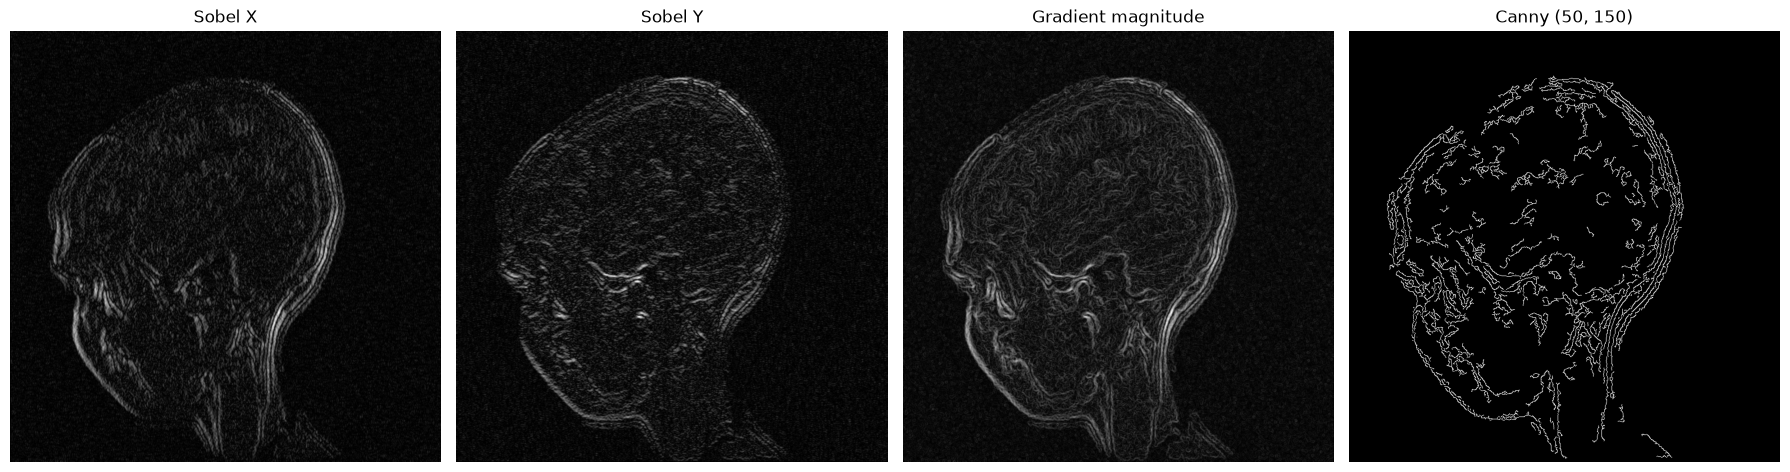

In [7]:
# Sobel on the Gaussian-noise image after Gaussian blur
smoothed = cv2.GaussianBlur(noisy_images["Gaussian noise"], (5, 5), 0)
gx = cv2.Sobel(smoothed, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(smoothed, cv2.CV_64F, 0, 1, ksize=3)
magnitude = cv2.magnitude(gx, gy)
mag_u8 = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
canny_edges = cv2.Canny(smoothed, T_LOWER, T_UPPER)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (im, title) in zip(axes, [(np.abs(gx), "Sobel X"), (np.abs(gy), "Sobel Y"),
                                  (mag_u8, "Gradient magnitude"), (canny_edges, f"Canny ({T_LOWER}, {T_UPPER})")]):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# Effect of the Canny hysteresis thresholds
sweep = []
for lo, hi in [(20, 60), (50, 150), (100, 200), (150, 250)]:
    e = cv2.Canny(smoothed, lo, hi)
    p, r, f1 = edge_scores(e, ref_edges)
    sweep.append({"T_lower": lo, "T_upper": hi, "Edge pixels": int((e > 0).sum()),
                  "Precision": round(p, 3), "Recall": round(r, 3), "F1": round(f1, 3)})
pd.DataFrame(sweep)

,T_lower,T_upper,Edge pixels,Precision,Recall,F1
0,20,60,83350,0.116,0.976,0.207
1,50,150,19404,0.407,0.819,0.544
2,100,200,5909,0.849,0.537,0.658
3,150,250,2726,0.933,0.278,0.429


## Task 4: YOLOv8 nano vs medium
Both models run on the same image. Latency is measured after one warm-up run so model loading time is not counted.

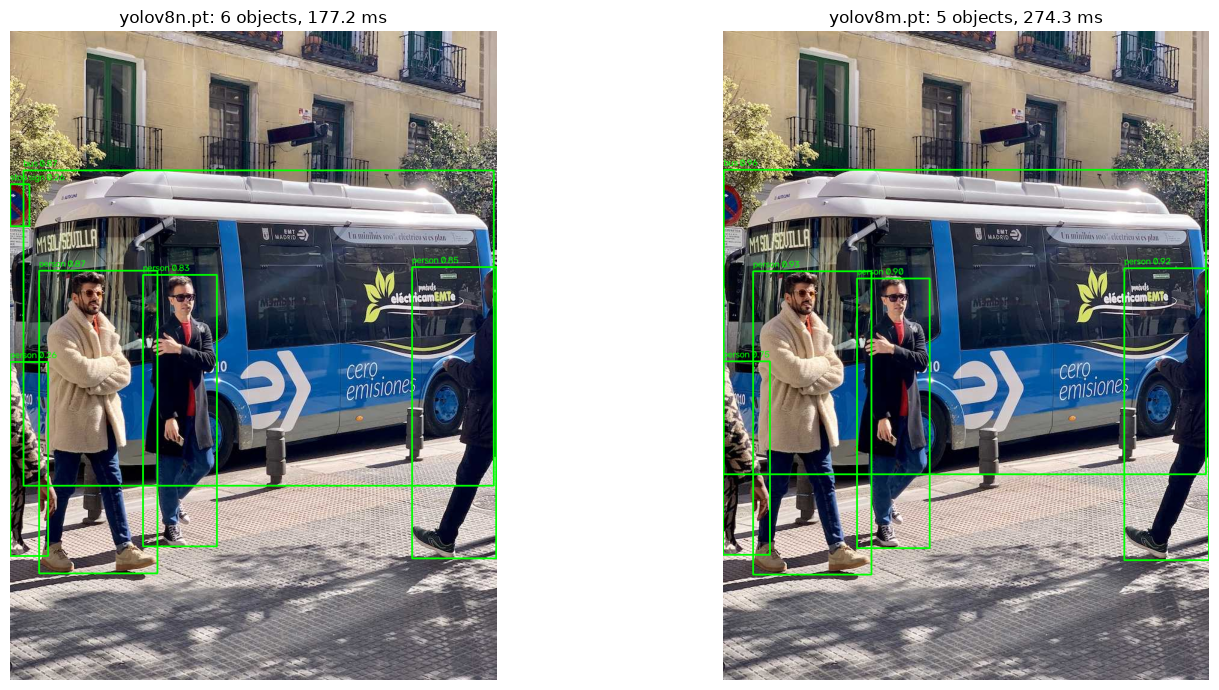

In [9]:
from ultralytics import YOLO

def detect_and_draw(model_name, image, conf=0.25):
    model = YOLO(model_name)
    model(image, verbose=False)                      # warm-up
    t0 = time.perf_counter()
    result = model(image, conf=conf, verbose=False)[0]
    latency_ms = (time.perf_counter() - t0) * 1000
    out = image.copy()
    dets = []
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        score, cls_id = float(box.conf[0]), int(box.cls[0])
        name = result.names[cls_id]
        dets.append({"class": name, "confidence": score, "bbox": (x1, y1, x2, y2)})
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(out, f"{name} {score:.2f}", (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    return out, dets, latency_ms

street = load_bgr(IMG_STREET)
runs = {}
for name in ["yolov8n.pt", "yolov8m.pt"]:
    runs[name] = detect_and_draw(name, street)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, (im, dets, ms)) in zip(axes, runs.items()):
    ax.imshow(to_rgb(im))
    ax.set_title(f"{name}: {len(dets)} objects, {ms:.1f} ms")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
table = []
for name, (im, dets, ms) in runs.items():
    counts = pd.Series([d["class"] for d in dets]).value_counts().to_dict()
    table.append({"Model": name, "Latency (ms)": round(ms, 1), "Total detections": len(dets),
                  "Classes found": len(counts), "Class counts": counts,
                  "Avg confidence": round(float(np.mean([d["confidence"] for d in dets])), 3) if dets else 0})
pd.DataFrame(table)

,Model,Latency (ms),Total detections,Classes found,Class counts,Avg confidence
0,yolov8n.pt,177.2,6,3,"{'person': 4, 'bus': 1, 'stop sign': 1}",0.656
1,yolov8m.pt,274.3,5,2,"{'person': 4, 'bus': 1}",0.892


In [11]:
# Box coordinates, confidence and label for the first 5 detections of each model
for name, (im, dets, ms) in runs.items():
    print(name)
    for d in dets[:5]:
        print(f"  {d['class']:<12} conf={d['confidence']:.2f}  bbox={d['bbox']}")

yolov8n.pt
  bus          conf=0.87  bbox=(22, 231, 805, 756)
  person       conf=0.87  bbox=(48, 398, 245, 902)
  person       conf=0.85  bbox=(669, 392, 809, 877)
  person       conf=0.83  bbox=(221, 405, 344, 857)
  person       conf=0.26  bbox=(0, 550, 63, 873)
yolov8m.pt
  bus          conf=0.96  bbox=(1, 230, 804, 737)
  person       conf=0.93  bbox=(50, 399, 247, 904)
  person       conf=0.92  bbox=(668, 394, 809, 880)
  person       conf=0.90  bbox=(223, 411, 344, 860)
  person       conf=0.75  bbox=(0, 549, 78, 871)


## Task 5: Retail shelf counting with class filtering
Detections are filtered in code to the target class IDs (COCO: 39 = bottle, 47 = apple) and counted only if confidence is at least 0.50.

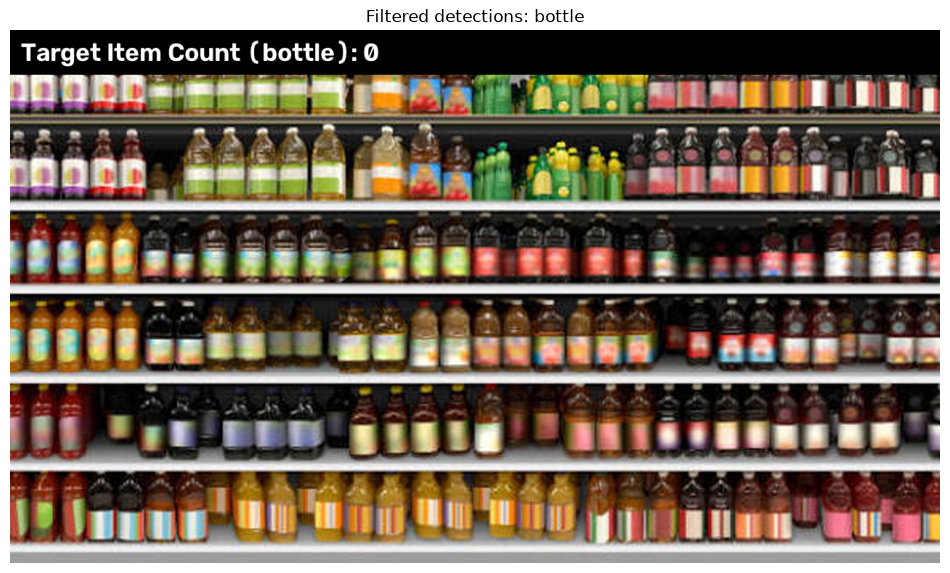

Target item count: 0


## Task 6: Intrusion alert with a polygon ROI
The ROI is defined as fractions of the image size so it works on any image. Change the `ROI_FRACTIONS` points to cover the area you want to protect.

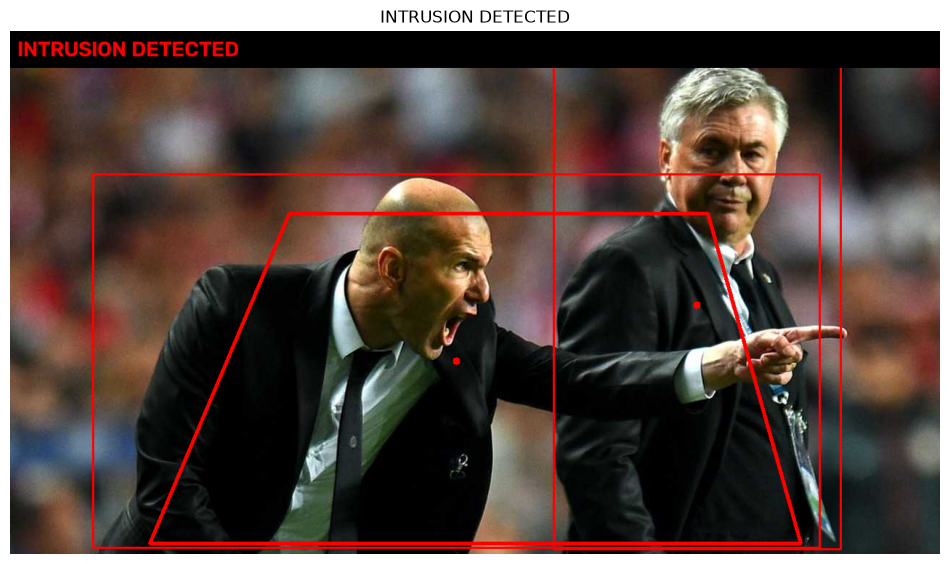

In [13]:
people = load_bgr(IMG_PEOPLE)
h, w = people.shape[:2]

ROI_FRACTIONS = [(0.30, 0.35), (0.75, 0.35), (0.85, 0.98), (0.15, 0.98)]
roi = np.array([(int(x * w), int(y * h)) for x, y in ROI_FRACTIONS], dtype=np.int32)

model6 = YOLO("yolov8n.pt")
res = model6(people, conf=0.4, classes=[0], verbose=False)[0]   # class 0 = person

out = people.copy()
intrusion = False
for box in res.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    xc, yc = (x1 + x2) / 2, (y1 + y2) / 2
    inside = cv2.pointPolygonTest(roi, (float(xc), float(yc)), False) >= 0
    intrusion = intrusion or inside
    color = (0, 0, 255) if inside else (255, 200, 0)
    cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
    cv2.circle(out, (int(xc), int(yc)), 5, color, -1)

roi_color = (0, 0, 255) if intrusion else (0, 255, 0)
cv2.polylines(out, [roi.reshape(-1, 1, 2)], isClosed=True, color=roi_color, thickness=3)
status = "INTRUSION DETECTED" if intrusion else "Area clear"
cv2.rectangle(out, (0, 0), (w, 50), (0, 0, 0), -1)
cv2.putText(out, status, (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.0, roi_color, 2)
cv2.imwrite(f"{OUT_DIR}/task6_intrusion_result.jpg", out)

plt.figure(figsize=(12, 8))
plt.imshow(to_rgb(out))
plt.title(status)
plt.axis("off")
plt.show()